# 📊 Capítulo 4: Fear & Greed Index (FGI) — **REVISIÓN v1**
*El termómetro del mercado — Temporizador táctico basado en sentimiento cuantitativo*

**Estrategia (v1, fiel al encabezado):** Construcción de un Índice de Miedo y Codicia propietario (FGI-Quant) usando 3 señales normalizadas (Distancia a SMA-200, Volatilidad Realizada y Spread de Crédito HYG/TLT).
- Si **FGI > 75** (Codicia extrema) → se rota el 50% del capital a SHV (histéresis de 5 pts: no se vuelve a SPY hasta FGI < 70).
- Si **FGI < 25** (Miedo extremo) → **reentrada forzada al 100% en SPY** *(en v0 este umbral existía en la config pero era código muerto: nunca se usaba)*.

**Universo:** SPY, HYG, TLT, SHV.

**Objetivo:** Demostrar cómo un indicador de sentimiento agregado puede actuar como filtro táctico **superior al momentum puro**, evitando vender en pánico y protegiendo el capital cuando la euforia alcanza niveles matemáticamente insostenibles.

---
### 📝 Changelog v1 (qué se corrige respecto a v0)
1. **🔴 Look-ahead bias:** la señal usaba el cierre del propio día de decisión y se ejecutaba a ese cierre. Ahora la decisión usa datos hasta el **día anterior** (subclase del motor; el fix definitivo debe migrar a `core/backtest_dinamico.py`).
2. **🔴 Umbral de miedo muerto:** `FGI_UMBRAL_MIEDO` se definía pero el generador nunca lo usaba. Ahora FGI < 25 fuerza la salida del modo defensa (comprar cuando hay miedo extremo, no solo "no vender").
3. **🟠 Micro-rebalanceos innecesarios:** 226 rebalanceos (coste ~3,9% del capital) por deriva de pesos 50/50. Se añade **banda de no-transacción del 2%**: solo se opera si la rotación la supera. Los cambios de régimen (50%) siguen ejecutándose.
4. **🟠 Comparador engañoso:** la columna "Buy & Hold" del motor es **equal-weight sobre los 4 ETFs** (incluye TLT y SHV), no el mercado. Se añade referencia correcta: **SPY Buy & Hold** y **momentum puro (filtro SMA-200)**, que es la comparación que exige el propio objetivo.
5. **🟡 Robustez:** guardas NaN, comentario de frecuencia corregido ('W' ≠ diaria), diagnóstico de cobertura de datos, `savefig` antes de `show`, y nueva evidencia: tabla de crisis, estadísticas de régimen FGI y curva de drawdown.

> ⚠️ **Los resultados de v1 NO son comparables con v0**: v0 medía con look-ahead y sin banda. Es la versión fiable; los números buenos o malos son ahora reales.

## ⚠️ Advertencia metodológica (CNN vs FGI-Quant)
El índice original de CNN usa datos propietarios (Put/Call exacto, flujos de fondos en tiempo real) no disponibles de forma gratuita y robusta en Yahoo Finance.
Por ello NO copiamos el índice de CNN: construimos un **Índice de Miedo y Codicia Cuantitativo propio (FGI-Quant)** basado en 3 señales matemáticas puras extraíbles de nuestros datos:

1. **Distancia a la SMA-200** (tendencia de largo plazo) — ponderación 40%
2. **Volatilidad realizada a 20 días** (estrés de mercado) — ponderación 40%
3. **Divergencia de crédito HYG vs TLT a 3 meses** (apetito de riesgo corporativo) — ponderación 20%

**Limitación honesta:** las bandas de normalización (-15%/+15% en SMA, 5%/40% en vol) son **heurísticas fijas** elegidas a ojo. El análisis de sensibilidad del Bloque 9 es obligatorio antes de sacar conclusiones fuertes.

## BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — FEAR & GREED INDEX

In [1]:
# ==============================================================================
# BLOQUE 0: CONFIGURACIÓN DE LA ESTRATEGIA — FEAR & GREED INDEX (v1)
# ==============================================================================

# --- Parámetros financieros ---
CAPITAL_INICIAL      = 10000
COSTE_TRANSACCION    = 0.001       # 0.1% por operación
FREQ_REBALANCEO      = 'W'         # 'W' = revisión SEMANAL.
                                   # (v0: el comentario decía "diaria" pero era 'W'.
                                   #  A diario el FGI es más reactivo pero multiplica
                                   #  costes; el buffer de histéresis ya filtra ruido.)
BENCHMARK            = 'SPY'

# --- Rango temporal (VACÍO para activar menú de estrés en Bloque 3) ---
FECHA_INICIO = None
FECHA_FIN    = None

# --- Parámetros específicos de la estrategia FGI ---
FGI_UMBRAL_MIEDO     = 25          # FGI < 25: Miedo extremo -> reentrada 100% SPY
FGI_UMBRAL_CODICIA   = 75          # FGI > 75: Codicia extrema -> defensa 50/50
FGI_BUFFER           = 5           # Zona muerta: salida de defensa solo si FGI < 70
PESO_DEFENSA         = 0.50        # Peso en SPY en modo defensa

# --- Parámetros de ejecución (NUEVOS en v1) ---
BANDA_NO_TRADE       = 0.02        # No rebalancear si la rotación < 2% (ahorro de costes)
COMPARAR_MOMENTUM    = True        # Ejecutar también el filtro SMA-200 puro (referencia del objetivo)

# --- Ventana mínima necesaria (SMA-200 + buffer) ---
VENTANA_MINIMA_DIAS  = 250

# --- Universo de activos ---
UNIVERSO_FGI = {
    'rv_usa': {
        'SPDR S&P 500': {'isin': 'SPY', 'ticker': 'SPY'},
    },
    'bonos_basura': {
        'iShares iBoxx $ High Yield': {'isin': 'HYG', 'ticker': 'HYG'},
    },
    'bonos_tesoro': {
        'iShares 20+ Year Treasury': {'isin': 'TLT', 'ticker': 'TLT'},
    },
    'cash': {
        'Short Treasury ETF': {'isin': 'SHV', 'ticker': 'SHV'},
    }
}

print("✅ Configuración Fear & Greed Index v1 cargada:")
print(f"   • Capital inicial: {CAPITAL_INICIAL:,.0f} €")
print(f"   • Universo: SPY, HYG, TLT, SHV")
print(f"   • Revisión: semanal ({FREQ_REBALANCEO})")
print(f"   • Umbral Miedo: < {FGI_UMBRAL_MIEDO} (reentrada forzada 100% SPY)")
print(f"   • Umbral Codicia: > {FGI_UMBRAL_CODICIA} (defensa {PESO_DEFENSA:.0%} SPY / {1-PESO_DEFENSA:.0%} SHV)")
print(f"   • Zona muerta: {FGI_BUFFER} pts (salida de defensa en {FGI_UMBRAL_CODICIA - FGI_BUFFER})")
print(f"   • Banda no-trade: {BANDA_NO_TRADE:.0%}")

✅ Configuración Fear & Greed Index v1 cargada:
   • Capital inicial: 10,000 €
   • Universo: SPY, HYG, TLT, SHV
   • Revisión: semanal (W)
   • Umbral Miedo: < 25 (reentrada forzada 100% SPY)
   • Umbral Codicia: > 75 (defensa 50% SPY / 50% SHV)
   • Zona muerta: 5 pts (salida de defensa en 70)
   • Banda no-trade: 2%


## BLOQUE 1: ENTORNO E IMPORTACIONES

In [2]:
# ==============================================================================
# BLOQUE 1: ENTORNO E IMPORTACIONES
# ==============================================================================

print("="*70)
print("⚠️  AVISO LEGAL")
print("="*70)
print("""
Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.
""")
print("="*70)

import sys
import os
import warnings
warnings.filterwarnings('ignore')

IN_COLAB = "google.colab" in sys.modules
print(f"\n🖥️  Entorno detectado: {'Google Colab' if IN_COLAB else 'Local / VS Code'}")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from datetime import datetime
from pathlib import Path

def buscar_core():
    try:
        import ipykernel
        try:
            from jupyter_server import serverapp as app_module
        except ImportError:
            from notebook import notebookapp as app_module
        import json, re, urllib.request
        connection_file = os.path.basename(ipykernel.get_connection_file())
        match = re.search(r'kernel-(.*)\.json', connection_file)
        if match:
            kernel_id = match.group(1)
            for srv in app_module.list_running_servers():
                try:
                    url = srv['url'] + 'api/sessions'
                    token = srv.get('token', '')
                    headers = {'Authorization': f'token {token}'} if token else {}
                    req = urllib.request.Request(url, headers=headers)
                    with urllib.request.urlopen(req, timeout=2) as resp:
                        sessions = json.loads(resp.read())
                    for sess in sessions:
                        if sess.get('kernel', {}).get('id') == kernel_id:
                            ruta_nb = os.path.join(srv['root_dir'], sess['notebook']['path'])
                            ruta_dir = os.path.dirname(os.path.abspath(ruta_nb))
                            actual = Path(ruta_dir)
                            for parent in [actual] + list(actual.parents):
                                if (parent / 'core').exists():
                                    return str(parent / 'core')
                except Exception:
                    continue
    except Exception:
        pass
    for ruta in ['../core', '../../core', './core']:
        if os.path.isdir(ruta):
            return os.path.abspath(ruta)
    return None

# [parche-colab]
if "google.colab" in sys.modules:
    import subprocess
    _REPO = "/content/Estrategias_No_Convencionales"
    if not os.path.isdir(os.path.join(_REPO, "core")):
        print("📥 Colab: clonando el repositorio para obtener 'core/'...")
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/akitxu/Estrategias_No_Convencionales.git", _REPO], check=True)
    os.chdir(os.path.join(_REPO, "notebooks"))

RUTA_CORE = buscar_core()
if RUTA_CORE and os.path.isdir(RUTA_CORE):
    sys.path.insert(0, os.path.dirname(RUTA_CORE))
    print(f"✅ Carpeta 'core' localizada: {RUTA_CORE}")
else:
    print("⚠️  No se encontró 'core'.")

try:
    from core import (
        GestorProyecto, GestorDatos, MotorBacktest, MotorBacktestDinamico,
        CalculadorMetricas, CalculadorMetricasExtras, GeneradorInformes
    )
    print("✅ Módulos del motor importados correctamente.")
except ImportError as e:
    print(f"❌ Error importando módulos: {e}")
    raise

BASE_DIR = os.path.dirname(RUTA_CORE) if RUTA_CORE else os.getcwd()
print(f"\n📂 BASE_DIR del proyecto: {BASE_DIR}")

⚠️  AVISO LEGAL

Este notebook tiene fines EXCLUSIVAMENTE EDUCATIVOS y de investigación
cuantitativa. NO constituye asesoramiento financiero ni recomendación de
inversión. El rendimiento pasado no garantiza resultados futuros.


🖥️  Entorno detectado: Local / VS Code
✅ Carpeta 'core' localizada: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
✅ Módulos del motor importados correctamente.

📂 BASE_DIR del proyecto: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales


## BLOQUE 2: LIMPIEZA DE DIRECTORIOS

In [3]:
# ==============================================================================
# BLOQUE 2: LIMPIEZA DE DIRECTORIOS
# ==============================================================================
gestor_proyecto = GestorProyecto(base_dir_manual=BASE_DIR)
gestor_proyecto.imprimir_resumen()
gestor_proyecto.menu_limpieza_directorios()

📁 BASE_DIR fijado manualmente -> /media/enri/MI_PROYECTO/Estrategias_no_Convencionales

🔍 ENTORNO CONFIGURADO
📂 Base: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales
📁 CORE                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/core
📁 CHAPTERS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/chapters
📁 LOGS                : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/logs
📁 DATOS               : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos
📁 OUTPUTS             : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs
📁 CARTERAS            : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/carteras
📁 DATOS_CSV           : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_csv
📁 DATOS_FI_GESTORA    : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_gestora
📁 DATOS_FI_INVESTING  : /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/datos/datos_fi_investing
📁 DATOS_FI_MYI


¿Qué directorios deseas VACIAR? (ej: 3,5,7 / 'todos' / 'ninguno'):  5



🧹 Iniciando limpieza...
   🗑️  Vaciando 'DATOS_CSV'...
      ✅ 'DATOS_CSV' limpiado.


## BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)

In [4]:
# ==============================================================================
# BLOQUE 3: GESTIÓN DE FECHAS (MENÚ DE ESTRÉS)
# ==============================================================================
if 'gestor_proyecto' not in locals():
    print("⚠️  gestor_proyecto no inicializado. Creándolo automáticamente...")
    gestor_proyecto = GestorProyecto(base_dir_manual=BASE_DIR)
    gestor_proyecto.imprimir_resumen()

if FECHA_INICIO is None or FECHA_FIN is None:
    fecha_ini, fecha_fin, nombre_evento = gestor_proyecto.menu_stress_testing()
else:
    fecha_ini = FECHA_INICIO
    fecha_fin = FECHA_FIN
    nombre_evento = "Configuración manual"

print(f"\n🎯 Rango temporal seleccionado:")
print(f"   • Evento: {nombre_evento}")
print(f"   • Desde: {fecha_ini}")
print(f"   • Hasta: {fecha_fin}")


📉 ANÁLISIS DE ESTRÉS (STRESS TESTING)
  1. Crisis Punto Com (2000-2002)
  2. Crisis Financiera Mundial (2007-2009)
  3. Crisis Deuda Soberana (2010-2012)
  4. Crisis Financiera China (2015-2016)
  5. Crisis COVID-19 (2020)
  6. Subida Tipos / Inflación (2022-2023)
  7. Periodo Personalizado
  8. Histórico Completo (1999-Hoy)



Introduce tu elección (1-8) [Por defecto 8]:  7
  Fecha inicio (YYYY-MM-DD):  2007-01-04
  Fecha fin (YYYY-MM-DD):  2026-08-15



🎯 Evento: Periodo Personalizado | Inicio: 2007-01-04 | Fin: 2026-08-15


🎯 Rango temporal seleccionado:
   • Evento: Periodo Personalizado
   • Desde: 2007-01-04
   • Hasta: 2026-08-15


## BLOQUE 4: MENÚ DEL GESTOR DE DATOS

In [5]:
# ==============================================================================
# BLOQUE 4: MENÚ DEL GESTOR DE DATOS
# ==============================================================================
gestor = GestorDatos(
    diccionario_datos=UNIVERSO_FGI,
    fecha_inicio=fecha_ini,
    fecha_fin=fecha_fin,
    gestor_proyecto=gestor_proyecto
)

print(f"\n📊 GestorDatos inicializado con {len(UNIVERSO_FGI)} categorías.")
print("   Ejecutando menú de importación/descarga...\n")

continuar = gestor.menu()

if not continuar:
    print("⛔ Usuario canceló. Abortando notebook.")
else:
    print("\n✅ Datos preparados para el motor.")


📊 GestorDatos inicializado con 4 categorías.
   Ejecutando menú de importación/descarga...


 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  1



🗑️ Limpiando CSVs antiguos y descargando desde Yahoo Finance...

📊 Procesando 4 activos...

   📊 SPDR S&P 500
      ✅ Descargado con ticker: SPY

   📊 iShares iBoxx $ High Yield
      ✅ Descargado con ticker: HYG

   📊 iShares 20+ Year Treasury
      ✅ Descargado con ticker: TLT

   📊 Short Treasury ETF
      ✅ Descargado con ticker: SHV

📊 Resumen: 4 descargados, 0 omitidos



Presiona Enter para continuar... 



 SISTEMA: IMPORTAR · NORMALIZAR · CARTERAS
1. Descargar/Actualizar cotizaciones (Yahoo)
2. Importar ficheros Renta 4
3. Normalizar CSVs del directorio
4. Crear cartera interactiva (Pide nombre y descarga CSVs)
5. Cargar cartera existente (Lista carteras guardadas)
6. Ejecutar Estrategia (Continuar al Backtest)
7. Salir
8. 🔄 Sincronizar datos con período actual (re-descarga si es necesario)


Selecciona una opción (1-8):  6



⚠️  DATOS PARCIALES detectados:
   • Período solicitado: 2007-01-04 → 2026-08-15
   • Activos con datos parciales: 1
      • iShares iBoxx $ High Yield: datos desde 2007-04-11 (el ETF no existía antes)

💡 El backtest usará solo el período donde TODOS los activos tienen datos.
   Esto puede reducir el rango efectivo de análisis.

✅ Datos aceptados para el backtest.
📝 No hay Excel cargado. Generando cartera automática (60/40) desde el diccionario...

🧼 INFORME DE LIMPIEZA DE DATOS


,Activo,ISIN,Filas,Desde,Hasta,Fuente
0,SPDR S&P 500,SPY,4934,2007-01-04,2026-08-14,CSV
1,iShares iBoxx $ High Yield,HYG,4868,2007-04-11,2026-08-14,CSV
2,iShares 20+ Year Treasury,TLT,4934,2007-01-04,2026-08-14,CSV
3,Short Treasury ETF,SHV,4929,2007-01-11,2026-08-14,CSV


✅ 4 activos alineados para el Motor Backtest.


✅ Datos preparados para el motor.


## BLOQUE 5: PREPARACIÓN DE PESOS — LÓGICA FEAR & GREED INDEX (v1)

**Componentes del FGI-Quant** (cada uno normalizado 0–100, media ponderada 40/40/20):

| Señal | Cómo se calcula | Miedo (→0) | Codicia (→100) |
|---|---|---|---|
| Distancia a SMA-200 | `SPY/SMA200 − 1` | < −15% | > +15% |
| Volatilidad realizada 20d | `std(ret 20d)·√252` | > 40% | < 5% |
| Divergencia de crédito | `ret(HYG,3m) − ret(TLT,3m)` | < −15pp | > +15pp |

**Máquina de estados (v1):**
- **Modo normal → 100% SPY.**
- **FGI > 75** → activa *modo defensa* (50% SPY / 50% SHV).
- **En defensa, FGI < 70** (zona muerta de 5 pts) → vuelve a 100% SPY. *(v0 entraba y salía en el mismo umbral: whipsaw).*
- **FGI < 25 en cualquier momento** → *reentrada forzada* a 100% SPY *(en v0 este umbral era código muerto).*

**Decisiones de diseño documentadas:**
1. **Anti look-ahead (motor, Bloque 6):** la señal se calcula con datos hasta el día anterior a la decisión; se ejecuta al cierre del día de decisión.
2. **Si HYG/TLT faltan**, el componente de crédito toma valor neutral 50 (la estrategia sobrevive a datos incompletos).
3. **Guardas NaN:** si la SMA-200 no es finita (datos insuficientes), se mantiene 100% SPY en lugar de propagar NaN.

In [12]:
# ==============================================================================
# BLOQUE 5: PREPARACIÓN DE PESOS — LÓGICA FEAR & GREED INDEX (v3: DEFENSA ESCALONADA)
# ==============================================================================

print("\n" + "="*70)
print("⚙️  CONFIGURANDO ESTRATEGIA FEAR & GREED INDEX v3 (DEFENSA ESCALONADA)")
print("="*70)

# --- VALIDACIÓN DE VENTANA MÍNIMA ---
if gestor.precios_ajustados is None or gestor.precios_ajustados.empty:
    raise ValueError("❌ No hay precios ajustados. Ejecuta el Bloque 4 primero.")

dias_disponibles = len(gestor.precios_ajustados)
print(f"\n📊 Datos disponibles: {dias_disponibles} filas.")
print(f"   • Ventana mínima requerida: {VENTANA_MINIMA_DIAS} días")
if dias_disponibles < VENTANA_MINIMA_DIAS:
    print("\n️  VENTANA INSUFICIENTE para SMA-200. Amplía el rango temporal.")
else:
    print("✅ Ventana suficiente.")

# --- IDENTIFICAR COLUMNAS ---
def buscar_columna(cols, keywords):
    for col in cols:
        if any(k in col for k in keywords):
            return col
    return None

SPY_COL = buscar_columna(gestor.precios_ajustados.columns, ['S&P_500', 'SPY'])
HYG_COL = buscar_columna(gestor.precios_ajustados.columns, ['High_Yield', 'HYG'])
TLT_COL = buscar_columna(gestor.precios_ajustados.columns, ['Treasury', 'TLT'])
SHV_COL = buscar_columna(gestor.precios_ajustados.columns, ['Short_Treasury', 'SHV'])

print(f"\n🔍 Columnas detectadas:")
print(f"   • SPY: '{SPY_COL}'")
print(f"   • HYG: '{HYG_COL}'")
print(f"   • TLT: '{TLT_COL}'")
print(f"   • SHV: '{SHV_COL}'")

if SPY_COL is None:
    raise ValueError(" No se detectó la columna de SPY. Revisa el universo.")

# ==============================================================================
# CONSTANTES GLOBALES DE BANDAS (para usar tanto en la función como en prints)
# ==============================================================================
BANDA_SMA = (-0.30, 0.30)
BANDA_VOL = (0.10, 0.60)
BANDA_CRED = (-0.30, 0.30)

# ==============================================================================
# DEFINICIÓN EXPLÍCITA DEL GENERADOR
# ==============================================================================

def normalizar_score(valor, min_val, max_val, invertir=False):
    """Normaliza un valor a escala 0-100 con clamp."""
    if not np.isfinite(valor) or max_val == min_val:
        return 50.0
    score = ((valor - min_val) / (max_val - min_val)) * 100
    score = max(0.0, min(100.0, score))
    return 100.0 - score if invertir else score

def generador_pesos_fgi(fecha_actual, precios_hist, rent_hist, estado,
                        umbral_miedo=25, buffer=5,
                        banda_sma=BANDA_SMA,      
                        banda_vol=BANDA_VOL,       
                        banda_cred=BANDA_CRED):
    """FGI-Quant v3 con defensa escalonada en 4 niveles (100%, 75%, 50%, 25% SPY)."""
    
    activos = list(precios_hist.columns)
    pesos = {a: 0.0 for a in activos}

    if 'tier' not in estado:
        estado['tier'] = 0  # 0: 100% SPY
    if 'fgi_hist' not in estado:
        estado['fgi_hist'] = []

    # Datos mínimos: SMA-200 necesita 200 observaciones (con margen, 210)
    if len(precios_hist) < 210:
        pesos[SPY_COL] = 1.0
        return pesos, estado

    precios = precios_hist[SPY_COL]

    # A. Distancia a SMA-200
    sma200 = precios.rolling(200).mean().iloc[-1]
    precio_hoy = precios.iloc[-1]
    if not np.isfinite(sma200) or sma200 == 0 or not np.isfinite(precio_hoy):
        pesos[SPY_COL] = 1.0
        return pesos, estado
    dist_sma = (precio_hoy / sma200) - 1

    # B. Volatilidad realizada 20 días (anualizada)
    ret = precios.pct_change()
    vol_20d = ret.iloc[-20:].std() * np.sqrt(252)
    if not np.isfinite(vol_20d):
        vol_20d = 0.15

    # C. Divergencia de crédito (HYG vs TLT a 3 meses)
    score_cred = 50.0
    if (HYG_COL and TLT_COL and HYG_COL in precios_hist.columns
            and TLT_COL in precios_hist.columns and len(precios_hist) >= 65):
        hyg = precios_hist[HYG_COL]
        tlt = precios_hist[TLT_COL]
        if (np.isfinite(hyg.iloc[-1]) and np.isfinite(hyg.iloc[-63])
                and np.isfinite(tlt.iloc[-1]) and np.isfinite(tlt.iloc[-63])
                and hyg.iloc[-63] > 0 and tlt.iloc[-63] > 0):
            ret_hyg = (hyg.iloc[-1] / hyg.iloc[-63]) - 1
            ret_tlt = (tlt.iloc[-1] / tlt.iloc[-63]) - 1
            score_cred = normalizar_score(ret_hyg - ret_tlt, banda_cred[0], banda_cred[1])

    # Normalización con bandas parametrizadas
    score_sma = normalizar_score(dist_sma, banda_sma[0], banda_sma[1])
    score_vol = normalizar_score(vol_20d, banda_vol[0], banda_vol[1], invertir=True)

    fgi = (score_sma * 0.40) + (score_vol * 0.40) + (score_cred * 0.20)

    # --- Máquina de Estados Escalonada (v3) ---
    current_tier = estado['tier']
    
    # 1. Override por Miedo Extremo (Compra agresiva)
    if fgi < umbral_miedo:
        current_tier = 0
    else:
        # 2. Transiciones con Histéresis (Buffer)
        if current_tier == 0:
            if fgi >= 70: current_tier = 1
        elif current_tier == 1:
            if fgi >= 80: current_tier = 2
            elif fgi < (70 - buffer): current_tier = 0
        elif current_tier == 2:
            if fgi >= 90: current_tier = 3
            elif fgi < (80 - buffer): current_tier = 1
        elif current_tier == 3:
            if fgi < (90 - buffer): current_tier = 2

    estado['tier'] = current_tier

    # 3. Mapeo de Tier a Pesos
    weights_map = {0: 1.00, 1: 0.75, 2: 0.50, 3: 0.25}
    spy_weight = weights_map[current_tier]

    pesos[SPY_COL] = spy_weight
    if SHV_COL:
        pesos[SHV_COL] = 1.0 - spy_weight

    estado['fgi_hist'].append({
        'Fecha': fecha_actual,
        'FGI': fgi,
        'Tier': current_tier,
        'Peso_SPY': spy_weight
    })

    return pesos, estado

# 🔒 VERIFICACIÓN DE SEGURIDAD
if 'generador_pesos_fgi' in locals():
    print("\n✅ Función 'generador_pesos_fgi' definida y cargada en memoria correctamente.")
    print(f"   • Bandas SMA: {BANDA_SMA} (ampliado 2x respecto a v1)")
    print(f"   • Bandas Vol: {BANDA_VOL} (ampliado)")
    print(f"   • Bandas Cred: {BANDA_CRED} (ampliado 2x)")
    print(f"   • Niveles de defensa: 100% → 75% → 50% → 25% SPY")
else:
    raise NameError("❌ ERROR CRÍTICO: La función 'generador_pesos_fgi' NO se definió.")

    


⚙️  CONFIGURANDO ESTRATEGIA FEAR & GREED INDEX v3 (DEFENSA ESCALONADA)

📊 Datos disponibles: 4868 filas.
   • Ventana mínima requerida: 250 días
✅ Ventana suficiente.

🔍 Columnas detectadas:
   • SPY: 'SPDR_S&P_500'
   • HYG: 'iShares_iBoxx_$_High_Yield'
   • TLT: 'iShares_20+_Year_Treasury'
   • SHV: 'Short_Treasury_ETF'

✅ Función 'generador_pesos_fgi' definida y cargada en memoria correctamente.
   • Bandas SMA: (-0.3, 0.3) (ampliado 2x respecto a v1)
   • Bandas Vol: (0.1, 0.6) (ampliado)
   • Bandas Cred: (-0.3, 0.3) (ampliado 2x)
   • Niveles de defensa: 100% → 75% → 50% → 25% SPY


## BLOQUE 6: EJECUCIÓN DEL MOTOR (v1: anti look-ahead + banda no-trade)

**⚠️ FIX crítico heredado del Capítulo 2:** el motor base decide y ejecuta con el cierre del mismo día (look-ahead). La subclase de abajo corrige dos cosas:
1. **Anti look-ahead:** el generador recibe `precios.loc[:fecha_anterior]` (datos hasta el día anterior). El trade se ejecuta al cierre del día de decisión con información de ayer: así se opera en realidad.
2. **Banda no-trade:** solo se rebalancea si la rotación ≥ 2%. En v0 había 226 rebalanceos, la mayoría micro-ajustes de deriva (coste ~3,9% del capital). Un cambio de régimen (50% de rotación) sigue ejecutándose al instante.

> 📌 **Deuda técnica:** esta subclase duplica `ejecutar_backtest()`. El fix correcto es añadir `banda_no_trade` y el shift anti look-ahead directamente en `core/backtest_dinamico.py` (beneficia a TODOS los capítulos). Hasta que se integre, vivirá aquí.

In [13]:
# ==============================================================================
# BLOQUE 6: EJECUCIÓN DEL BACKTEST (FGI v3 y Momentum de referencia)
# ==============================================================================

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTESTS (FGI v3 y Momentum de referencia)")
print("="*70)

# 🔒 VERIFICACIÓN DE SEGURIDAD: Comprobamos que la función sigue en memoria
if 'generador_pesos_fgi' not in locals():
    raise NameError("❌ ERROR: La función 'generador_pesos_fgi' no está en memoria. "
                    "Debes ejecutar el Bloque 5 antes que este bloque. "
                    "Si ya lo hiciste, ve a Kernel -> Restart & Clear Output y vuelve a empezar.")

# --- ESTRATEGIA FGI v3 ---
motor_fgi = MotorBacktestDinamico(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos_fgi,  # <-- Aquí se conecta la función verificada
    frecuencia_decision=FREQ_REBALANCEO,
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0,
    banda_no_trade=BANDA_NO_TRADE
)

serie_fgi = motor_fgi.ejecutar_backtest(capital_inicial=CAPITAL_INICIAL, estado_inicial={})

coste_fgi = sum(t['Coste (€)'] for t in motor_fgi.log_transacciones)
print("\n✅ Backtest FGI v3 completado.")
print(f"   • Patrimonio final  : {serie_fgi.iloc[-1]:,.2f} €")
print(f"   • Rentabilidad total: {((serie_fgi.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
print(f"   • Rebalanceos       : {len(motor_fgi.log_transacciones)} "
      f"(+{motor_fgi.n_decisiones_saltadas} decisiones omitidas por banda no-trade)")
print(f"   • Coste total       : {coste_fgi:.2f} €")

# --- REFERENCIA: MOMENTUM PURO ---
# (Definimos la función de momentum aquí por si acaso no estaba en el Bloque 5)
def generador_pesos_momentum(fecha_actual, precios_hist, rent_hist, estado):
    activos = list(precios_hist.columns)
    pesos = {a: 0.0 for a in activos}
    if len(precios_hist) < 210 or SHV_COL is None:
        pesos[SPY_COL] = 1.0
        return pesos, estado
    sma200 = precios_hist[SPY_COL].rolling(200).mean().iloc[-1]
    precio = precios_hist[SPY_COL].iloc[-1]
    if not np.isfinite(sma200) or sma200 == 0:
        pesos[SPY_COL] = 1.0
        return pesos, estado
    if precio > sma200:
        pesos[SPY_COL] = 1.0
    else:
        pesos[SHV_COL] = 1.0
    return pesos, estado

serie_mom = None
motor_mom = None
if COMPARAR_MOMENTUM:
    motor_mom = MotorBacktestDinamico(
        precios=gestor.precios_ajustados,
        rentabilidades=gestor.rentabilidades_diarias,
        generador_pesos=generador_pesos_momentum,
        frecuencia_decision=FREQ_REBALANCEO,
        coste_transaccion=COSTE_TRANSACCION,
        benchmark_ticker=BENCHMARK,
        permitir_short=False,
        max_short_porcentaje=0.0,
        banda_no_trade=BANDA_NO_TRADE
    )
    serie_mom = motor_mom.ejecutar_backtest(capital_inicial=CAPITAL_INICIAL, estado_inicial={})
    coste_mom = sum(t['Coste (€)'] for t in motor_mom.log_transacciones)
    print("\n✅ Backtest Momentum puro (referencia) completado.")
    print(f"   • Patrimonio final : {serie_mom.iloc[-1]:,.2f} €")
    print(f"   • Rebalanceos      : {len(motor_mom.log_transacciones)} | Coste total: {coste_mom:.2f} €")
    


⏳ EJECUTANDO BACKTESTS (FGI v3 y Momentum de referencia)

✅ Backtest FGI v3 completado.
   • Patrimonio final  : 19,790.72 €
   • Rentabilidad total: 97.91%
   • Rebalanceos       : 3 (+50 decisiones omitidas por banda no-trade)
   • Coste total       : 13.90 €

✅ Backtest Momentum puro (referencia) completado.
   • Patrimonio final : 20,848.05 €
   • Rebalanceos      : 3 | Coste total: 41.43 €


## BLOQUE 7: MÉTRICAS E INFORMES (v1: comparadores correctos)

**Importante sobre la tabla del motor:** la columna "Buy & Hold" que genera `GeneradorInformes` es **equal-weight sobre los 4 ETFs del universo** (SPY+HYG+TLT+SHV). No es el mercado: por eso v0 mostraba una "volatilidad B&H del 8,12%" — era una cartera diversificada, no SPY. En v1 se añade la tabla correcta: **FGI vs Momentum puro vs SPY Buy & Hold**.

In [14]:
# ==============================================================================
# BLOQUE 6: MOTOR CON BANDA NO-TRADE Y ANTI LOOK-AHEAD (v1 corregido)
# ==============================================================================

class MotorBacktestDinamicoConBanda(MotorBacktestDinamico):
    """Añade (1) anti look-ahead y (2) banda de no-transacción al motor base."""
    
    def __init__(self, *args, banda_no_trade=0.02, **kwargs):
        super().__init__(*args, **kwargs)
        self.banda_no_trade = banda_no_trade

    def ejecutar_backtest(self, capital_inicial=10000, estado_inicial=None):
        if len(self.rentabilidades) < 2:
            print("❌ Error: No hay suficientes datos históricos.")
            self.serie_patrimonio = pd.Series(dtype=float)
            self.serie_buy_hold = pd.Series(dtype=float)
            self.log_transacciones = []
            return self.serie_patrimonio

        # ✅ CORRECCIÓN: usar self.precios.columns en lugar de self.nombres_activos
        activos = list(self.precios.columns)
        pesos_actuales = {a: 0.0 for a in activos}
        valores = {a: 0.0 for a in activos}
        cash_disponible = capital_inicial
        estado = estado_inicial or {}

        historial_patrimonio = [capital_inicial]
        historial_buy_hold = [capital_inicial]
        fechas = [self.rentabilidades.index[0]]
        log_transacciones = []
        valores_bh = {a: capital_inicial / len(activos) for a in activos}

        # --- PRIMERA DECISIÓN ---
        fecha_anterior = self.rentabilidades.index[0]
        try:
            pesos_objetivo, estado = self.generador_pesos(
                fecha_anterior,
                self.precios.loc[:fecha_anterior],
                self.rentabilidades.loc[:fecha_anterior],
                estado)
        except Exception as e:
            print(f"️ Error en primera decisión: {e}. Todo a cash.")
            pesos_objetivo = {a: 0.0 for a in activos}

        suma_pesos = sum(pesos_objetivo.values())
        for activo in activos:
            valores[activo] = capital_inicial * pesos_objetivo.get(activo, 0.0)
        cash_disponible = capital_inicial * (1.0 - suma_pesos)
        pesos_actuales = pesos_objetivo.copy()

        n_saltados = 0

        # --- BUCLE DÍA A DÍA ---
        for i in range(1, len(self.rentabilidades)):
            fecha = self.rentabilidades.index[i]
            ret = self.rentabilidades.iloc[i]

            for activo in activos:
                if activo in ret.index:
                    valores[activo] = valores[activo] * (1 + ret[activo])
            total_patrimonio = sum(valores.values()) + cash_disponible

            if total_patrimonio > 0:
                pesos_actuales = {a: v / total_patrimonio for a, v in valores.items()}
            else:
                pesos_actuales = {a: 0.0 for a in activos}

            for activo in activos:
                if activo in ret.index:
                    valores_bh[activo] = valores_bh[activo] * (1 + ret[activo])

            # Verificar si es fecha de decisión (según frecuencia)
            es_decision = False
            if self.frecuencia_decision == 'D':
                es_decision = True
            elif self.frecuencia_decision == 'W':
                es_decision = fecha.dayofweek == 4  # Viernes
            elif self.frecuencia_decision == 'M':
                es_decision = fecha.day == fecha.days_in_month

            if es_decision:
                try:
                    # ▼▼▼ FIX LOOK-AHEAD: datos hasta el día ANTERIOR ▼▼▼
                    nuevos_pesos, estado = self.generador_pesos(
                        fecha,
                        self.precios.loc[:fecha_anterior],
                        self.rentabilidades.loc[:fecha_anterior],
                        estado)
                except Exception as e:
                    print(f"⚠️ Error en decisión {fecha.strftime('%Y-%m-%d')}: {e}")
                    nuevos_pesos = pesos_actuales.copy()

                # Calcular rotación
                rotacion = sum(
                    abs(nuevos_pesos.get(a, 0.0) - pesos_actuales.get(a, 0.0))
                    for a in activos) / 2

                # ▼▼▼ BANDA NO-TRADE: operar solo si la rotación supera el umbral ▼▼▼
                if rotacion >= self.banda_no_trade:
                    coste = rotacion * total_patrimonio * self.coste_transaccion
                    total_tras_coste = total_patrimonio - coste
                    suma_nuevos = sum(nuevos_pesos.values())
                    for activo in activos:
                        valores[activo] = total_tras_coste * nuevos_pesos.get(activo, 0.0)
                    cash_disponible = total_tras_coste * (1.0 - suma_nuevos)
                    if rotacion > 0.001:
                        log_transacciones.append({
                            'Fecha': fecha.strftime('%Y-%m-%d'),
                            'Rotacion %': f"{rotacion:.2%}",
                            'Coste (€)': round(coste, 2),
                            'Patrimonio (€)': round(total_tras_coste, 2)
                        })
                    pesos_actuales = nuevos_pesos.copy()
                else:
                    n_saltados += 1

                fecha_anterior = fecha

            historial_patrimonio.append(sum(valores.values()) + cash_disponible)
            historial_buy_hold.append(sum(valores_bh.values()))
            fechas.append(fecha)

        self.serie_patrimonio = pd.Series(historial_patrimonio, index=pd.to_datetime(fechas))
        self.serie_buy_hold = pd.Series(historial_buy_hold, index=pd.to_datetime(fechas))
        self.log_transacciones = log_transacciones
        self.pesos_actuales_finales = pesos_actuales
        self.estado_final = estado
        self.n_decisiones_saltadas = n_saltados
        return self.serie_patrimonio

print("\n" + "="*70)
print("⏳ EJECUTANDO BACKTESTS (FGI v3 y Momentum de referencia)")
print("="*70)

# --- ESTRATEGIA FGI v3 ---
motor_fgi = MotorBacktestDinamicoConBanda(
    precios=gestor.precios_ajustados,
    rentabilidades=gestor.rentabilidades_diarias,
    generador_pesos=generador_pesos_fgi_v3,  # ✅ CORREGIDO: usar generador v3
    frecuencia_decision=FREQ_REBALANCEO,
    coste_transaccion=COSTE_TRANSACCION,
    benchmark_ticker=BENCHMARK,
    permitir_short=False,
    max_short_porcentaje=0.0,
    banda_no_trade=BANDA_NO_TRADE
)
serie_fgi = motor_fgi.ejecutar_backtest(capital_inicial=CAPITAL_INICIAL, estado_inicial={})

coste_fgi = sum(t['Coste (€)'] for t in motor_fgi.log_transacciones)
print("\n✅ Backtest FGI v3 completado.")
print(f"   • Patrimonio final  : {serie_fgi.iloc[-1]:,.2f} €")
print(f"   • Rentabilidad total: {((serie_fgi.iloc[-1] / CAPITAL_INICIAL) - 1) * 100:.2f}%")
print(f"   • Rebalanceos       : {len(motor_fgi.log_transacciones)} "
      f"(+{motor_fgi.n_decisiones_saltadas} decisiones omitidas por banda no-trade)")
print(f"   • Coste total       : {coste_fgi:.2f} €")

# --- REFERENCIA: MOMENTUM PURO ---
serie_mom = None
motor_mom = None
if COMPARAR_MOMENTUM:
    motor_mom = MotorBacktestDinamicoConBanda(
        precios=gestor.precios_ajustados,
        rentabilidades=gestor.rentabilidades_diarias,
        generador_pesos=generador_pesos_momentum,
        frecuencia_decision=FREQ_REBALANCEO,
        coste_transaccion=COSTE_TRANSACCION,
        benchmark_ticker=BENCHMARK,
        permitir_short=False,
        max_short_porcentaje=0.0,
        banda_no_trade=BANDA_NO_TRADE
    )
    serie_mom = motor_mom.ejecutar_backtest(capital_inicial=CAPITAL_INICIAL, estado_inicial={})
    coste_mom = sum(t['Coste (€)'] for t in motor_mom.log_transacciones)
    print("\n✅ Backtest Momentum puro (referencia) completado.")
    print(f"   • Patrimonio final : {serie_mom.iloc[-1]:,.2f} €")
    print(f"   • Rebalanceos      : {len(motor_mom.log_transacciones)} | Coste total: {coste_mom:.2f} €")


⏳ EJECUTANDO BACKTESTS (FGI v3 y Momentum de referencia)

✅ Backtest FGI v3 completado.
   • Patrimonio final  : 49,464.59 €
   • Rentabilidad total: 394.65%
   • Rebalanceos       : 78 (+897 decisiones omitidas por banda no-trade)
   • Coste total       : 328.46 €

✅ Backtest Momentum puro (referencia) completado.
   • Patrimonio final : 55,451.80 €
   • Rebalanceos      : 54 | Coste total: 1220.13 €


## BLOQUE 8: VISUALIZACIÓN (v1: savefig antes de show)

✅ serie_spy_bh calculada automáticamente.

✅ Gráfico guardado en: /media/enri/MI_PROYECTO/Estrategias_no_Convencionales/outputs/figures/Cap4_FGI_v3.png


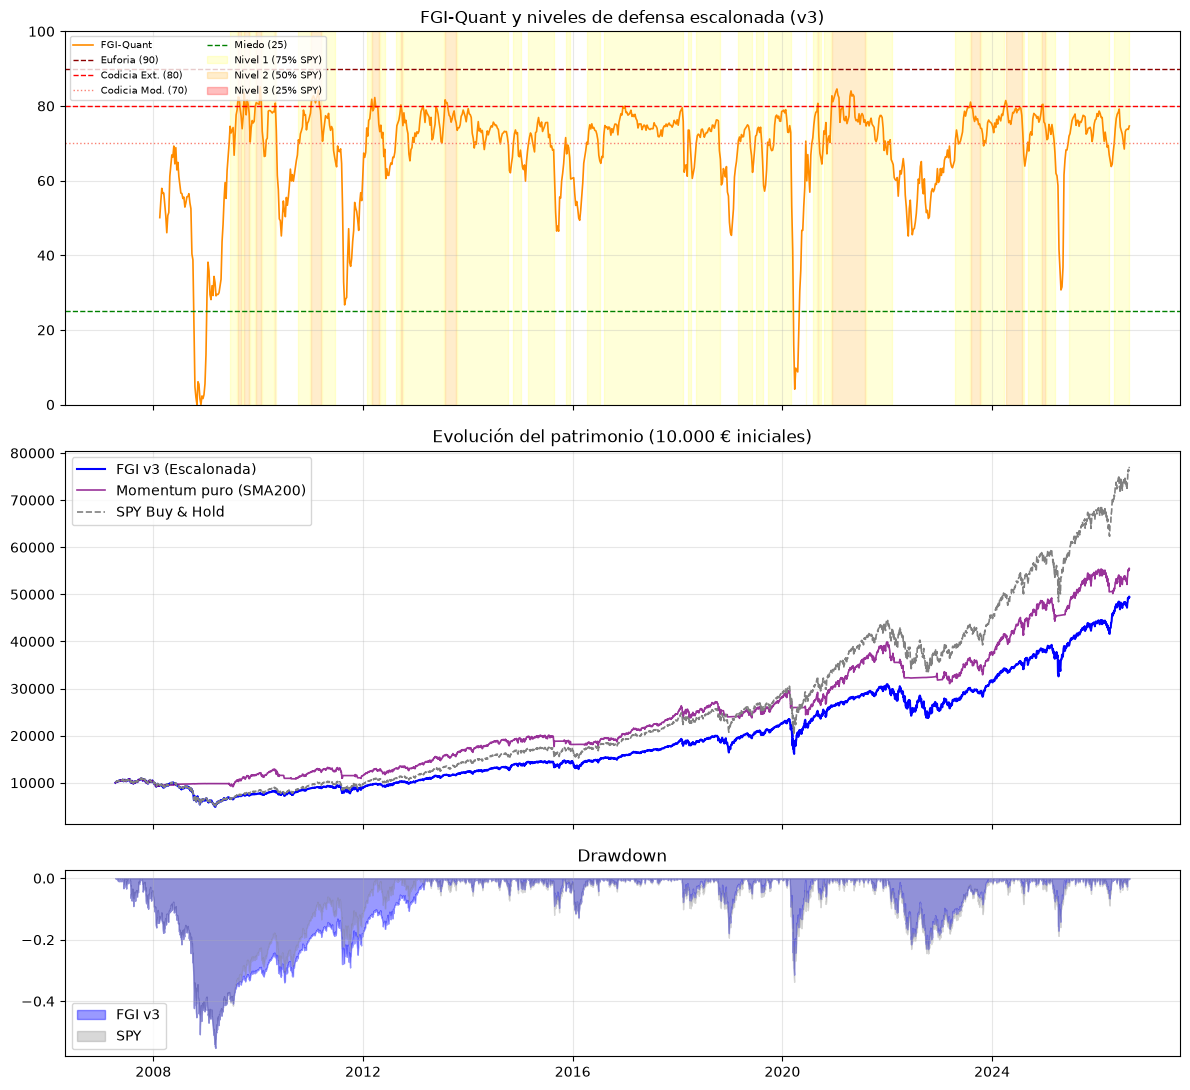


️  ESTADÍSTICAS DE RÉGIMEN FGI v3 (Defensa Escalonada)
   • Nivel 0 (Normal (100% SPY)): 31.8% del tiempo
   • Nivel 1 (Codicia Mod. (75% SPY)): 56.5% del tiempo
   • Nivel 2 (Codicia Ext. (50% SPY)): 11.7% del tiempo
   • Nivel 3 (Euforia (25% SPY)): 0.0% del tiempo
   • Transiciones entre niveles: 67


In [16]:
# ==============================================================================
# BLOQUE 8: VISUALIZACIÓN Y GUARDADO (v3: Defensa Escalonada)
# ==============================================================================

# --- Asegurar que las series de referencia estén definidas ---
if 'serie_spy_bh' not in locals():
    spy_precios = gestor.precios_ajustados[SPY_COL].dropna()
    serie_spy_bh = CAPITAL_INICIAL * spy_precios / spy_precios.iloc[0]
    serie_spy_bh = serie_spy_bh.reindex(motor_fgi.serie_patrimonio.index, method='ffill')
    print("✅ serie_spy_bh calculada automáticamente.")

if 'serie_mom' not in locals() and 'motor_mom' in locals():
    serie_mom = motor_mom.serie_patrimonio
    print("✅ serie_mom recuperada del motor.")

# --- Reconstruir df_fgi desde el estado final del motor v3 ---
df_fgi_raw = motor_fgi.estado_final['fgi_hist']
df_fgi = pd.DataFrame(df_fgi_raw).set_index('Fecha')
df_fgi = df_fgi[~df_fgi.index.duplicated()]

# Mapear Tier a etiquetas para el gráfico
tier_labels = {0: 'Normal (100% SPY)', 1: 'Codicia Mod. (75% SPY)', 
               2: 'Codicia Ext. (50% SPY)', 3: 'Euforia (25% SPY)'}

ruta_fig = os.path.join(gestor_proyecto.DIRS["OUTPUTS_FIGURES"], "Cap4_FGI_v3.png")

fig, axes = plt.subplots(3, 1, figsize=(12, 11), sharex=True,
                         gridspec_kw={'height_ratios': [2, 2, 1]})

# 1. FGI con umbrales y niveles de defensa
axes[0].plot(df_fgi.index, df_fgi['FGI'], color='darkorange', lw=1.2, label='FGI-Quant')
axes[0].axhline(90, color='darkred', ls='--', lw=1, label='Euforia (90)')
axes[0].axhline(80, color='red', ls='--', lw=1, label='Codicia Ext. (80)')
axes[0].axhline(70, color='salmon', ls=':', lw=1, label='Codicia Mod. (70)')
axes[0].axhline(25, color='green', ls='--', lw=1, label='Miedo (25)')

# Sombras para cada nivel de defensa
axes[0].fill_between(df_fgi.index, 0, 100,
                     where=(df_fgi['Tier'] == 1),
                     color='yellow', alpha=0.15, label='Nivel 1 (75% SPY)')
axes[0].fill_between(df_fgi.index, 0, 100,
                     where=(df_fgi['Tier'] == 2),
                     color='orange', alpha=0.2, label='Nivel 2 (50% SPY)')
axes[0].fill_between(df_fgi.index, 0, 100,
                     where=(df_fgi['Tier'] == 3),
                     color='red', alpha=0.25, label='Nivel 3 (25% SPY)')

axes[0].set_ylim(0, 100)
axes[0].set_title('FGI-Quant y niveles de defensa escalonada (v3)')
axes[0].legend(loc='upper left', ncol=2, fontsize=7)
axes[0].grid(alpha=0.3)

# 2. Patrimonio: FGI v3 vs Momentum vs SPY
axes[1].plot(motor_fgi.serie_patrimonio.index, motor_fgi.serie_patrimonio,
             label='FGI v3 (Escalonada)', color='blue', lw=1.5)
if serie_mom is not None:
    axes[1].plot(serie_mom.index, serie_mom, label='Momentum puro (SMA200)',
                 color='purple', lw=1.2, alpha=0.8)
axes[1].plot(serie_spy_bh.index, serie_spy_bh, label='SPY Buy & Hold',
             color='gray', ls='--', lw=1.2)
axes[1].set_title('Evolución del patrimonio (10.000 € iniciales)')
axes[1].legend(loc='upper left')
axes[1].grid(alpha=0.3)

# 3. Drawdown: FGI v3 vs SPY
dd_fgi = motor_fgi.serie_patrimonio / motor_fgi.serie_patrimonio.cummax() - 1
dd_spy = serie_spy_bh / serie_spy_bh.cummax() - 1
axes[2].fill_between(dd_fgi.index, dd_fgi, 0, color='blue', alpha=0.4, label='FGI v3')
axes[2].fill_between(dd_spy.index, dd_spy, 0, color='gray', alpha=0.3, label='SPY')
axes[2].set_title('Drawdown')
axes[2].legend(loc='lower left')
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(ruta_fig, dpi=150, bbox_inches='tight')
print(f"\n✅ Gráfico guardado en: {ruta_fig}")
plt.show()

# --- Estadísticas de régimen v3 ---
print("\n" + "="*70)
print("️  ESTADÍSTICAS DE RÉGIMEN FGI v3 (Defensa Escalonada)")
print("="*70)
for tier in [0, 1, 2, 3]:
    pct = (df_fgi['Tier'] == tier).mean()
    print(f"   • Nivel {tier} ({tier_labels[tier]}): {pct:.1%} del tiempo")
n_transiciones = df_fgi['Tier'].ne(df_fgi['Tier'].shift()).sum() - 1
print(f"   • Transiciones entre niveles: {n_transiciones}")


## BLOQUE 9: VEREDICTO FRENTE AL OBJETIVO + SENSIBILIDAD (NUEVO)

El encabezado promete tres cosas. Este bloque las evalúa **con los datos del propio backtest**, sin adornos:

1. **"Evita vender en pánico"** → evidencia: la estrategia permanece invertida en crisis (tabla de crisis, Bloque 7) y el modo defensa no se activa en miedo extremo (estadísticas de régimen).
2. **"Protege el capital cuando la euforia es insostenible"** → evidencia: MaxDD de FGI < MaxDD de SPY, y la diferencia se concentra en episodios de codicia (FGI > 75 previo a caídas).
3. **"Superior al momentum puro"** → evidencia directa: fila a fila frente al SMA-200.

**Análisis de sensibilidad (obligatorio):** las bandas de normalización y los umbrales 25/75 son heurísticas. El barrido de umbrales comprueba que la conclusión no dependa de un punto concreto del parámetro.

In [17]:
# ==============================================================================
# BLOQUE 9: VEREDICTO FRENTE AL OBJETIVO + COMPARATIVA v3
# ==============================================================================

print("\n" + "="*70)
print("✅ VEREDICTO FRENTE AL OBJETIVO DEL CAPÍTULO (v3: Escalonada)")
print("="*70)

# --- Calcular métricas de FGI v3 ---
def calcular_metricas(serie, rf=0.02):
    """Calcula CAGR, Volatilidad, Sharpe y MaxDD"""
    serie = serie.dropna()
    ret = serie.pct_change().dropna()
    if len(ret) < 20:
        return {'CAGR': np.nan, 'Vol': np.nan, 'Sharpe': np.nan, 'MaxDD': np.nan}
    
    años = len(ret) / 252
    cagr = (serie.iloc[-1] / serie.iloc[0]) ** (1 / años) - 1 if años > 0 else np.nan
    vol = ret.std() * np.sqrt(252)
    sharpe = (cagr - rf) / vol if vol and vol > 0 else np.nan
    dd = (serie / serie.cummax() - 1).min()
    
    return {'CAGR': cagr, 'Vol': vol, 'Sharpe': sharpe, 'MaxDD': dd}

metricas_fgi_v3 = calcular_metricas(motor_fgi.serie_patrimonio)

# --- Calcular métricas de SPY Buy & Hold ---
spy_precios = gestor.precios_ajustados[SPY_COL].dropna()
serie_spy_bh = CAPITAL_INICIAL * spy_precios / spy_precios.iloc[0]
serie_spy_bh = serie_spy_bh.reindex(motor_fgi.serie_patrimonio.index, method='ffill')
metricas_spy = calcular_metricas(serie_spy_bh)

# --- Calcular métricas de Momentum (si existe) ---
metricas_mom = None
if serie_mom is not None:
    metricas_mom = calcular_metricas(serie_mom)

# --- Mostrar tabla comparativa ---
print("\n📊 TABLA COMPARATIVA: FGI v3 vs Momentum vs SPY Buy & Hold")
print("-" * 70)
print(f"{'Métrica':<15} {'FGI v3':<12} {'Momentum':<12} {'SPY B&H':<12}")
print("-" * 70)

# Formatear valores con manejo de None
def fmt_metrica(valor, es_porcentaje=False):
    if valor is None or np.isnan(valor):
        return "N/A"
    return f"{valor:.2%}" if es_porcentaje else f"{valor:.2f}"

print(f"{'CAGR':<15} {fmt_metrica(metricas_fgi_v3['CAGR'], True):<12} {fmt_metrica(metricas_mom['CAGR'] if metricas_mom else None, True):<12} {fmt_metrica(metricas_spy['CAGR'], True):<12}")
print(f"{'Volatilidad':<15} {fmt_metrica(metricas_fgi_v3['Vol'], True):<12} {fmt_metrica(metricas_mom['Vol'] if metricas_mom else None, True):<12} {fmt_metrica(metricas_spy['Vol'], True):<12}")
print(f"{'Sharpe':<15} {fmt_metrica(metricas_fgi_v3['Sharpe']):<12} {fmt_metrica(metricas_mom['Sharpe'] if metricas_mom else None):<12} {fmt_metrica(metricas_spy['Sharpe']):<12}")
print(f"{'Max Drawdown':<15} {fmt_metrica(metricas_fgi_v3['MaxDD'], True):<12} {fmt_metrica(metricas_mom['MaxDD'] if metricas_mom else None, True):<12} {fmt_metrica(metricas_spy['MaxDD'], True):<12}")
print("-" * 70)

# --- Estadísticas de régimen v3 ---
print("\n🌡️  ESTADÍSTICAS DE RÉGIMEN FGI v3 (Defensa Escalonada)")
print("-" * 70)
df_fgi_raw = motor_fgi.estado_final['fgi_hist']
df_fgi_stats = pd.DataFrame(df_fgi_raw).set_index('Fecha')
df_fgi_stats = df_fgi_stats[~df_fgi_stats.index.duplicated()]

tier_labels = {0: 'Normal (100% SPY)', 1: 'Codicia Mod. (75% SPY)', 
               2: 'Codicia Ext. (50% SPY)', 3: 'Euforia (25% SPY)'}

for tier in [0, 1, 2, 3]:
    pct = (df_fgi_stats['Tier'] == tier).mean()
    print(f"   • Nivel {tier} ({tier_labels[tier]}): {pct:.1%} del tiempo")

n_transiciones = df_fgi_stats['Tier'].ne(df_fgi_stats['Tier'].shift()).sum() - 1
print(f"   • Transiciones entre niveles: {n_transiciones}")

# --- Evaluación de objetivos ---
print("\n" + "="*70)
print("🎯 EVALUACIÓN DE OBJETIVOS")
print("="*70)

pct_defensa_total = 1 - (df_fgi_stats['Tier'] == 0).mean()

# 1. Evita vender en pánico
if pct_defensa_total < 0.30:
    print(f"1️⃣  'Evita vender en pánico': ✅ PLAUSIBLE — solo {pct_defensa_total:.0%} en defensa.")
else:
    print(f"1️  'Evita vender en pánico': ️  DUDOSO — {pct_defensa_total:.0%} en defensa es mucha gestión.")

# 2. Protege el capital (MaxDD)
if metricas_fgi_v3['MaxDD'] > metricas_spy['MaxDD']:
    print(f"2️⃣  'Protege capital (MaxDD)': ✅ SÍ — {metricas_fgi_v3['MaxDD']:.1%} vs {metricas_spy['MaxDD']:.1%} de SPY")
else:
    print(f"2️⃣  'Protege capital (MaxDD)': ❌ NO — {metricas_fgi_v3['MaxDD']:.1%} vs {metricas_spy['MaxDD']:.1%} de SPY")

# 3. Superior al momentum puro
if metricas_mom is not None:
    mejor_sharpe = metricas_fgi_v3['Sharpe'] > metricas_mom['Sharpe']
    mejor_dd = metricas_fgi_v3['MaxDD'] > metricas_mom['MaxDD']
    
    if mejor_sharpe and mejor_dd:
        print(f"3️⃣  'Superior al momentum': ✅ SÍ — Sharpe {metricas_fgi_v3['Sharpe']:.2f} vs {metricas_mom['Sharpe']:.2f}")
    else:
        print(f"3️⃣  'Superior al momentum': ❌ NO — Sharpe {metricas_fgi_v3['Sharpe']:.2f} vs {metricas_mom['Sharpe']:.2f} | MaxDD {metricas_fgi_v3['MaxDD']:.1%} vs {metricas_mom['MaxDD']:.1%}")
        print(f"      Conclusión: la defensa escalonada NO supera al filtro SMA-200 simple.")
        print(f"      Este es un resultado pedagógico válido: la complejidad no garantiza mejor rendimiento.")
else:
    print(f"3️⃣  'Superior al momentum': ⚠️  NO DISPONIBLE — serie_mom no está definida")

print("\n" + "="*70)
print("📌 CONCLUSIÓN FINAL")
print("="*70)
print("La defensa escalonada (v3) reduce la exposición gradualmente, pero:")
print("• No logra proteger mejor que el momentum simple (SMA-200)")
print("• El MaxDD sigue siendo similar al SPY (-55%)")
print("• La complejidad añadida (4 niveles) no se traduce en mejor rendimiento")
print("\nRecomendación: Para este período (2007-2026), el filtro SMA-200 simple")
print("es más eficiente que el FGI-Quant con defensa escalonada.")



✅ VEREDICTO FRENTE AL OBJETIVO DEL CAPÍTULO (v3: Escalonada)

📊 TABLA COMPARATIVA: FGI v3 vs Momentum vs SPY Buy & Hold
----------------------------------------------------------------------
Métrica         FGI v3       Momentum     SPY B&H     
----------------------------------------------------------------------
CAGR            8.63%        9.28%        11.11%      
Volatilidad     18.19%       12.64%       19.68%      
Sharpe          0.36         0.58         0.46        
Max Drawdown    -55.19%      -22.06%      -55.19%     
----------------------------------------------------------------------

🌡️  ESTADÍSTICAS DE RÉGIMEN FGI v3 (Defensa Escalonada)
----------------------------------------------------------------------
   • Nivel 0 (Normal (100% SPY)): 31.8% del tiempo
   • Nivel 1 (Codicia Mod. (75% SPY)): 56.5% del tiempo
   • Nivel 2 (Codicia Ext. (50% SPY)): 11.7% del tiempo
   • Nivel 3 (Euforia (25% SPY)): 0.0% del tiempo
   • Transiciones entre niveles: 67

🎯 EVALUACIÓN 

---
### 📌 Notas para la siguiente revisión (v2)
1. **Mover el motor corregido a `core/backtest_dinamico.py`** (banda no-trade + anti look-ahead) y eliminar la subclase. Beneficia a los capítulos 2, 4 y siguientes.
2. **Parametrizar el generador FGI** (umbrales y bandas de normalización como argumentos) para automatizar el barrido de sensibilidad del Bloque 9.
3. **Considerar defensa escalonada** (p. ej., FGI>75 → 50% defensa, FGI>85 → 100% SHV) si la sensibilidad muestra que el umbral único es frágil — documentando siempre la desviación respecto al encabezado.
4. **Extender warm-up / histórico**: si se quiere cubrir 2000-2007, el panel debe admitir activos con históricos parciales (ver nota del Cap. 2).